In [6]:
from google.colab import drive
drive.mount('/content/drive')
!pip install -q river
import os, sys, glob, json, shutil, time, pickle, importlib, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

QUICK    = False
ROOT     = "/content/drive/MyDrive/dtn_project"
RES_A    = f"{ROOT}/results"
RES_B    = f"{ROOT}/results_b"
LOCAL    = "/content/processed"
WINDOW, SEED = 12, 0
DATASETS = ["5g", "4g", "operator"]
COLSET   = {"5g": "single", "4g": "single", "operator": "value+daily"}
NAMES    = {"5g": ["DL_bitrate"], "4g": ["DL_bitrate"], "operator": None}
RECENT   = {"5g": 600, "4g": 600, "operator": 576}
SHORT    = {"5g": 150, "4g": 150, "operator": 144}
FT       = dict(ft_epochs=5, ft_lr=5e-4, ft_batch=128)
DEFAULT_KW = dict(delta=0.002, alpha=0.005, window_size=100, stat_size=30)
MAX_RETRAINS = 50
ADWIN_DELTAS = [0.002, 0.01, 0.05, 0.2, 0.5]
KSWIN_ALPHAS = [0.0005, 0.005, 0.05]

SUF = "_quick" if QUICK else ""
CACHE = f"{RES_B}/ablation_cache{SUF}"
os.makedirs(CACHE, exist_ok=True)
if not os.path.exists(LOCAL): shutil.copytree(f"{ROOT}/processed", LOCAL)
for ds in DATASETS: print(ds, len(glob.glob(f"{LOCAL}/{ds}/*.npz")), "traces")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
5g 79 traces
4g 134 traces
operator 55 traces


## 2. Load models, traces and the configurations
- Reads the same trace list as Experiment 2 and the best model per dataset.
- Lists every configuration to run (name, detector, setting, how much data a retrain uses).
- `metrics` is copied exactly from Member A.

**You should see:** one model per dataset, the traces, and the number of configurations (10 per trace).

In [7]:
sys.path.append(ROOT + "/src")
import neural; importlib.reload(neural)
import retrain_b as R; importlib.reload(R)
print("Device:", neural.DEVICE)

def metrics(y, p, last):
    y, p, last = (np.asarray(a, dtype="float64") for a in (y, p, last))
    err = p - y
    ss = ((y - y.mean()) ** 2).sum()
    ch = y - last; m = ch != 0
    return dict(MAE=np.abs(err).mean(), RMSE=np.sqrt((err ** 2).mean()),
                R2=1 - (err ** 2).sum() / ss if ss > 0 else np.nan,
                dir_acc=(np.sign(p - last)[m] == np.sign(ch)[m]).mean() if m.any() else np.nan)

def load_trace(ds, name):
    d = f"{LOCAL}/{ds}"; sc = json.load(open(f"{d}/scaler.json"))
    cols = list(range(len(sc["cols"]))) if NAMES[ds] is None else [sc["cols"].index(n) for n in NAMES[ds]]
    z = np.load(f"{d}/{name}.npz"); tr, va, te = (z[s][:, cols].astype("float32") for s in ("train", "val", "test"))
    X, y = R.make_windows(te, WINDOW, context=va)
    return dict(arr=np.vstack([tr, va, te]), n0=len(tr) + len(va), X=X, y=y, mu0=sc["mean"][0], sd0=sc["std"][0])

bm = pd.read_csv(f"{RES_A}/best_models.csv").drop_duplicates(["dataset", "model"]).sort_values(["dataset", "val_loss"])
MODEL = {ds: bm[bm.dataset == ds].model.iloc[0] for ds in DATASETS}          # the single best model per dataset
M0 = {ds: neural.load_model(f"{RES_A}/models/{ds}__{COLSET[ds]}__{MODEL[ds]}__s{SEED}.pt")[0] for ds in DATASETS}
tl = pd.read_csv(f"{RES_B}/exp2_traces{SUF}.csv")
SUBSET = {ds: list(tl[tl.dataset == ds].trace) for ds in DATASETS}
if QUICK: SUBSET = {ds: v[:3] for ds, v in SUBSET.items()}

CONFIGS = []        # name, ablation, detector, detector settings, recent-window label
for d in ADWIN_DELTAS: CONFIGS.append((f"adwin delta={d}", "A_adwin_sensitivity", "adwin", dict(delta=d), "default"))
for a in KSWIN_ALPHAS: CONFIGS.append((f"kswin alpha={a}", "B_kswin_sensitivity", "kswin", dict(alpha=a), "default"))
CONFIGS.append(("kswin recent=short", "C_recent_window", "kswin", dict(alpha=0.005), "short"))
CONFIGS.append(("kswin recent=all", "C_recent_window", "kswin", dict(alpha=0.005), "all"))
for ds in DATASETS: print(f"{ds}: model {MODEL[ds]} | {len(SUBSET[ds])} traces")
print(len(CONFIGS), "configurations per trace (plus the 'none' reference)")

Device: cuda
5g: model lstm | 20 traces
4g: model gru | 20 traces
operator: model gru | 20 traces
10 configurations per trace (plus the 'none' reference)


## 3. Run the ablations
For each dataset and trace it first replays `none` (the reference), then every configuration. Each finished trace is **saved straight away** in `ablation_cache/`; if Colab disconnects, run the cell again and it continues.

The very sensitive settings fire often and are slower (each retrain takes about 0.1 s, at most 50 per trace). If a setting hits the cap of 50 retrains, it is flagged in the results.

**You should see:** one line per trace with the time taken.

In [8]:
def recent_for(ds, label):
    return {"default": RECENT[ds], "short": SHORT[ds], "all": None}[label]

def run_unit(ds, trace):
    T = load_trace(ds, trace); m0 = M0[ds]; out = {}
    def go(strategy, det_kw, recent):
        neural.set_seed(SEED)
        p, al, rs, cap = R.replay(m0, T["X"], T["y"], T["arr"], T["n0"], strategy, window=WINDOW, det_kw=det_kw,
                                  recent=recent, max_retrains=MAX_RETRAINS, **FT)
        return dict(pred=(p * T["sd0"] + T["mu0"]).astype("float32"), alarms=al, retrain_s=rs, capped=cap)
    out["none"] = go("none", {}, RECENT[ds])
    for name, abl, det, kw, rl in CONFIGS:
        out[name] = go(det, kw, recent_for(ds, rl))
    return dict(y=(T["y"] * T["sd0"] + T["mu0"]).astype("float32"),
                last=(T["X"][:, -1, 0] * T["sd0"] + T["mu0"]).astype("float32"), runs=out)

t_start, n_new = time.time(), 0
for ds in DATASETS:
    for tr in SUBSET[ds]:
        f = f"{CACHE}/{ds}__{tr}.pkl"
        if os.path.exists(f): continue
        t0 = time.time(); pickle.dump(run_unit(ds, tr), open(f, "wb")); n_new += 1
        print(f"{ds} {tr[:30]}: done ({time.time() - t0:.0f}s)")
print(f"\nfinished {n_new} new traces in {(time.time() - t_start) / 60:.1f} min")

5g Amazon_Prime__Driving__Season3: done (1s)
5g Amazon_Prime__Driving__Season3: done (0s)
5g Amazon_Prime__Driving__Season3: done (3s)
5g Amazon_Prime__Static__Season3-: done (8s)
5g Amazon_Prime__Static__animated: done (1s)
5g Amazon_Prime__Static__animated: done (3s)
5g Download__Driving__B_2019.12.1: done (1s)
5g Download__Driving__B_2020.01.1: done (2s)
5g Download__Driving__B_2020.02.1: done (0s)
5g Download__Static__B_2020.02.14: done (1s)
5g Netflix__Driving__Season3-Stra: done (2s)
5g Netflix__Driving__Season3-Stra: done (1s)
5g Netflix__Driving__Season3-Stra: done (1s)
5g Netflix__Driving__Season3-Stra: done (1s)
5g Netflix__Driving__animated-Ric: done (3s)
5g Netflix__Driving__animated-Ric: done (0s)
5g Netflix__Static__Season3-Stran: done (3s)
5g Netflix__Static__Season3-Stran: done (7s)
5g Netflix__Static__Season3-Stran: done (2s)
5g Netflix__Static__animated-Rick: done (7s)
4g bus__A_2018.01.26_11.26.26: done (2s)
4g bus__B_2018.01.25_19.50.43: done (0s)
4g car__A_2017.12.

## 4. Collect the results
Reads the cache and computes the metrics per trace (same layout as before). Saves:
- `ablation_trace_results.csv`: one row per trace and configuration (for the statistics tests),
- `ablation_summary.csv`: the table below.

**How to read it:** `d_RMSE_%` is the change in mean RMSE versus `none` on the same traces (negative = better). `retrains` is the average per trace, `retrain_s` the total seconds, `capped` the number of traces that hit the 50-retrain cap.

**You should see:** a table per ablation and dataset. For ADWIN, check whether more sensitive settings finally produce retrains and whether that helps.

In [9]:
CFG = {c[0]: c for c in CONFIGS}
rows = []
for f in sorted(glob.glob(f"{CACHE}/*.pkl")):
    ds, tr = os.path.basename(f)[:-4].split("__", 1)
    u = pickle.load(open(f, "rb"))
    for name, r in u["runs"].items():
        c = CFG.get(name)
        rows.append(dict(trace=tr, n=len(u["y"]), **metrics(u["y"], r["pred"], u["last"]), dataset=ds, model=MODEL[ds],
                         config=name, ablation=c[1] if c else "reference", detector=c[2] if c else "none",
                         recent=c[4] if c else "default", n_retrains=len(r["alarms"]), retrain_s=r["retrain_s"],
                         capped=int(r["capped"])))
res = pd.DataFrame(rows); res.to_csv(f"{RES_B}/ablation_trace_results{SUF}.csv", index=False)

S = res.groupby(["dataset", "config"]).agg(RMSE=("RMSE", "mean"), MAE=("MAE", "mean"), R2_median=("R2", "median"),
        dir_acc=("dir_acc", "mean"), retrains=("n_retrains", "mean"), retrain_s=("retrain_s", "sum"),
        capped=("capped", "sum"), traces=("trace", "nunique")).reset_index()
base = S[S.config == "none"].set_index("dataset").RMSE
S["d_RMSE_%"] = [100 * (r.RMSE / base[r.dataset] - 1) for r in S.itertuples()]
ORDER = ["none"] + [c[0] for c in CONFIGS]
S["config"] = pd.Categorical(S.config, ORDER, ordered=True); S = S.sort_values(["dataset", "config"])
S.to_csv(f"{RES_B}/ablation_summary{SUF}.csv", index=False)
pd.set_option("display.width", 200)
for ds in DATASETS:
    print(f"\n=== {ds} (model: {MODEL[ds]}) ===")
    print(S[S.dataset == ds].drop(columns=["dataset"]).round(3).to_string(index=False))


=== 5g (model: lstm) ===
            config     RMSE      MAE  R2_median  dir_acc  retrains  retrain_s  capped  traces  d_RMSE_%
              none 8882.933 5000.893      0.011    0.615      0.00      0.000       0      20     0.000
 adwin delta=0.002 8882.933 5000.893      0.011    0.615      0.00      0.000       0      20     0.000
  adwin delta=0.01 8883.000 5000.944      0.011    0.615      0.05      0.082       0      20     0.001
  adwin delta=0.05 8884.821 5008.426      0.011    0.614      0.10      0.157       0      20     0.021
   adwin delta=0.2 8884.331 5008.307      0.011    0.614      0.10      0.153       0      20     0.016
   adwin delta=0.5 8901.011 5020.308      0.011    0.614      0.35      0.548       0      20     0.204
kswin alpha=0.0005 8874.697 5067.523     -0.040    0.613      1.55      2.777       0      20    -0.093
 kswin alpha=0.005 8874.436 5074.213     -0.015    0.614      2.40      4.025       0      20    -0.096
  kswin alpha=0.05 8855.560 5078.137  

## 5. Plots
- **Left/middle/right (one per dataset):** change in RMSE against the number of retrains, for ADWIN and KSWIN at every sensitivity setting. A line that goes down as retrains increase means more retraining helps; a flat or rising line means it only adds cost.
- **Second figure:** recent window (short, default, all data) for KSWIN: RMSE change and retraining seconds.

**You should see:** two figures, also saved as PNG in `results_b/`.

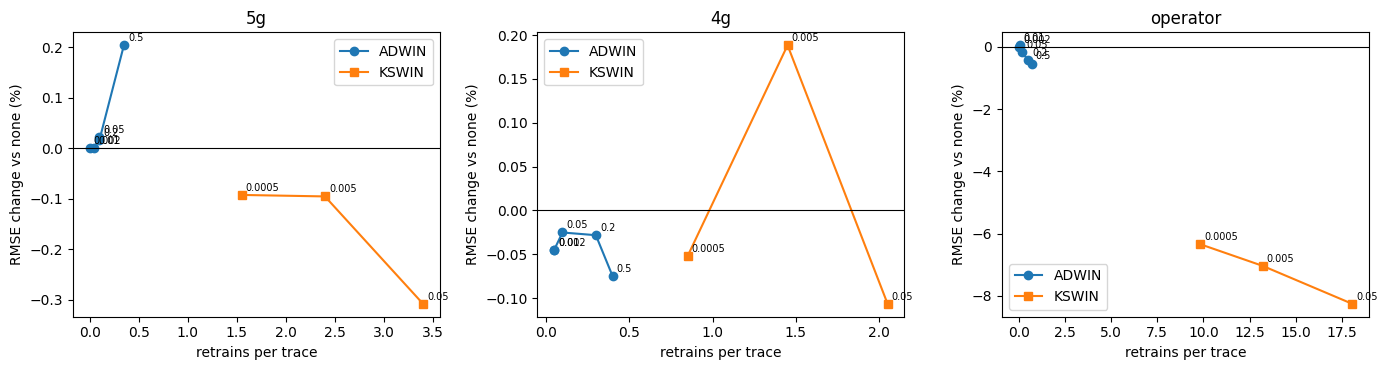

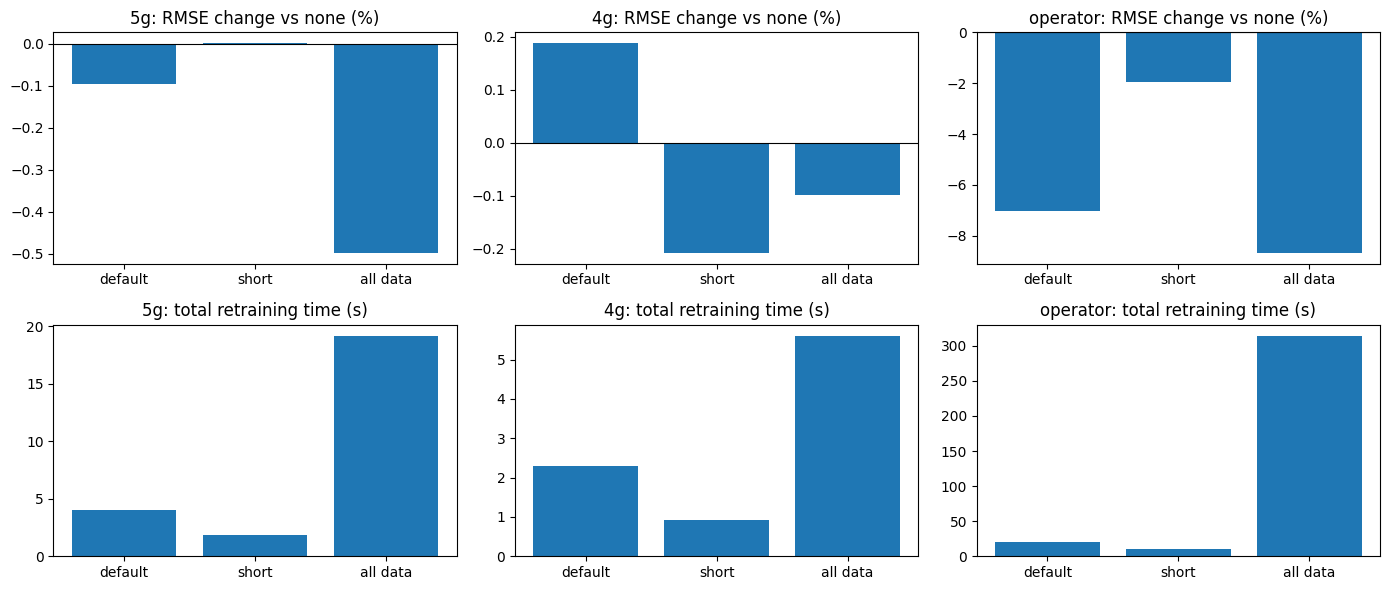

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, ds in zip(axes, DATASETS):
    s = S[S.dataset == ds]
    for det, mk in (("adwin", "o-"), ("kswin", "s-")):
        sub = s[s.config.astype(str).str.startswith(det) & ~s.config.astype(str).str.contains("recent")]
        sub = sub.sort_values("retrains")
        ax.plot(sub.retrains, sub["d_RMSE_%"], mk, label=det.upper())
        for x, yv, c in zip(sub.retrains, sub["d_RMSE_%"], sub.config.astype(str)):
            ax.annotate(c.split("=")[1], (x, yv), fontsize=7, xytext=(3, 3), textcoords="offset points")
    ax.axhline(0, c="k", lw=0.8); ax.set_title(f"{ds}"); ax.set_xlabel("retrains per trace"); ax.set_ylabel("RMSE change vs none (%)")
    ax.legend()
plt.tight_layout(); plt.savefig(f"{RES_B}/plot_ablation_sensitivity{SUF}.png", dpi=150, bbox_inches="tight"); plt.show()

names = ["kswin alpha=0.005", "kswin recent=short", "kswin recent=all"]; lab = ["default", "short", "all data"]
fig, axes = plt.subplots(2, 3, figsize=(14, 6))
for j, ds in enumerate(DATASETS):
    s = S[S.dataset == ds].set_index(S[S.dataset == ds].config.astype(str)).loc[names]
    axes[0, j].bar(lab, s["d_RMSE_%"]); axes[0, j].axhline(0, c="k", lw=0.8)
    axes[0, j].set_title(f"{ds}: RMSE change vs none (%)")
    axes[1, j].bar(lab, s["retrain_s"]); axes[1, j].set_title(f"{ds}: total retraining time (s)")
plt.tight_layout(); plt.savefig(f"{RES_B}/plot_ablation_recent{SUF}.png", dpi=150, bbox_inches="tight"); plt.show()